In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


🎯 Loading dataset from verified path: /kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv
🚀 Success! Training Features Shape: (5634, 30)


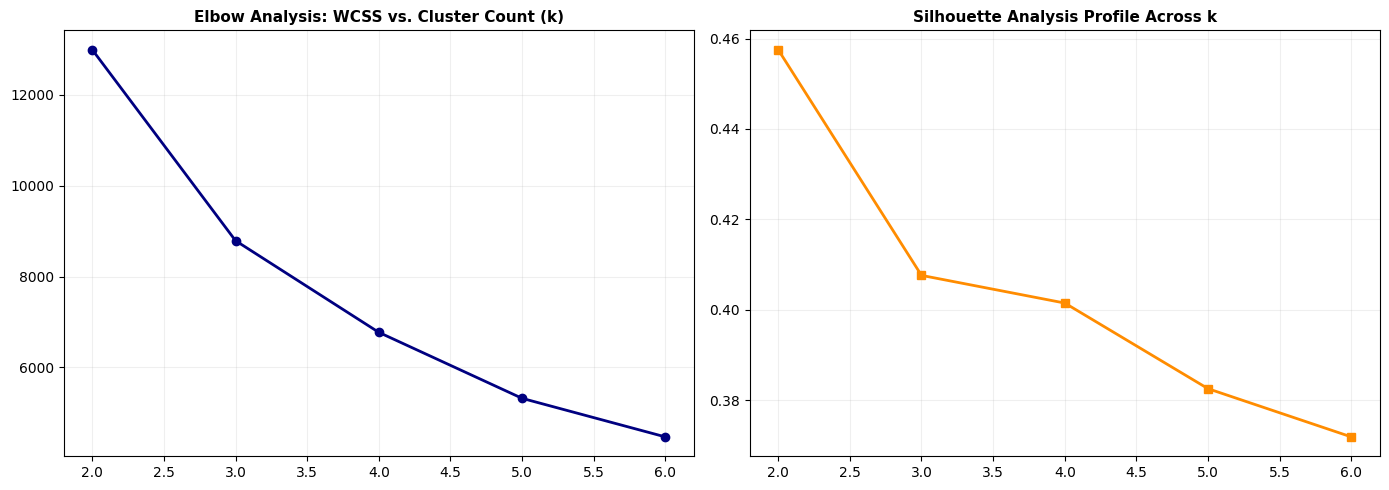


=== Structured Customer Segments Profile (k=4) ===
 Cluster_ID  Customer_Count  Avg_Tenure_Months  Avg_Monthly_Bill  Avg_Services_Count  Observed_Churn_Rate
          0            1030             53.614            30.959               1.480                0.046
          1            2157             18.375            80.409               3.284                0.430
          2            1938             59.830            92.087               5.057                0.145
          3            1918              8.959            37.706               1.203                0.320

📊 PCA Dimensionality Insight: 15 of 30 components explain 90% variance.


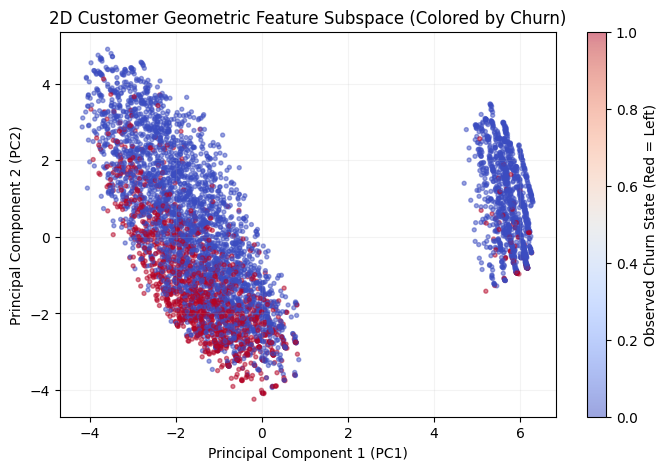

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

# ----------------------------------------------------------------------
# 1. FIXED DATA INFRASTRUCTURE LAYER
# ----------------------------------------------------------------------
# Direct path to the official attached Kaggle dataset
dataset_path = '/kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv'

# Fallback auto-detector in case folder casing differs slightly
if not os.path.exists(dataset_path):
    for root, dirs, files in os.walk('/kaggle/input'):
        for file in files:
            if 'telco' in file.lower() and file.endswith('.csv'):
                dataset_path = os.path.join(root, file)

print(f"🎯 Loading dataset from verified path: {dataset_path}")
df = pd.read_csv(dataset_path)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)
y = (df['Churn'] == 'Yes').astype(int)

# Rebuild feature matrices
X_raw = df.drop(columns=['customerID', 'Churn'])
X = pd.get_dummies(X_raw, drop_first=True).astype(float)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"🚀 Success! Training Features Shape: {X_train.shape}")

# ----------------------------------------------------------------------
# 2. PART 5: K-MEANS CUSTOMER SEGMENTATION
# ----------------------------------------------------------------------
seg_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
service_columns = ['PhoneService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                   'TechSupport', 'StreamingTV', 'StreamingMovies']

df_seg = df[seg_features].copy()
df_seg['n_services'] = (df[service_columns] == 'Yes').sum(axis=1)

scaler_z = StandardScaler()
Z_scaled = scaler_z.fit_transform(df_seg)

cluster_range = range(2, 7)
inertia_scores = []
silhouette_avgs = []

for k in cluster_range:
    km_engine = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z_scaled)
    inertia_scores.append(km_engine.inertia_)
    silhouette_avgs.append(silhouette_score(Z_scaled, km_engine.labels_, sample_size=3000, random_state=42))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(cluster_range, inertia_scores, marker='o', color='navy', linewidth=2)
axes[0].set_title('Elbow Analysis: WCSS vs. Cluster Count (k)', fontsize=11, weight='bold')
axes[0].grid(True, alpha=0.2)

axes[1].plot(cluster_range, silhouette_avgs, marker='s', color='darkorange', linewidth=2)
axes[1].set_title('Silhouette Analysis Profile Across k', fontsize=11, weight='bold')
axes[1].grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

optimal_k = 4
final_kmeans = KMeans(n_clusters=optimal_k, n_init=10, random_state=42).fit(Z_scaled)
df_seg['Cluster_ID'] = final_kmeans.labels_

cluster_profiles = df_seg.assign(Churn_Label=y).groupby('Cluster_ID').agg(
    Customer_Count=('tenure', 'size'),
    Avg_Tenure_Months=('tenure', 'mean'),
    Avg_Monthly_Bill=('MonthlyCharges', 'mean'),
    Avg_Services_Count=('n_services', 'mean'),
    Observed_Churn_Rate=('Churn_Label', 'mean')
).reset_index()

print(f"\n=== Structured Customer Segments Profile (k={optimal_k}) ===")
print(cluster_profiles.round(3).to_string(index=False))

# ----------------------------------------------------------------------
# 3. PART 6: PRINCIPAL COMPONENT ANALYSIS (PCA)
# ----------------------------------------------------------------------
X_train_scaled = StandardScaler().fit_transform(X_train)

pca_full = PCA().fit(X_train_scaled)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
components_for_90 = np.argmax(cumulative_variance >= 0.90) + 1
print(f"\n📊 PCA Dimensionality Insight: {components_for_90} of {X_train.shape[1]} components explain 90% variance.")

pca_2d = PCA(n_components=2)
T_coordinates = pca_2d.fit_transform(X_train_scaled)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(T_coordinates[:, 0], T_coordinates[:, 1], c=y_train, cmap='coolwarm', s=8, alpha=0.5)
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.title('2D Customer Geometric Feature Subspace (Colored by Churn)')
plt.colorbar(scatter, label='Observed Churn State (Red = Left)')
plt.grid(True, alpha=0.15)
plt.show()


In [3]:
import joblib
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import roc_auc_score, recall_score, precision_score

# 1. Establish production CV validation bounds
cv_framework = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Instantiate the optimized Logistic Regression pipeline as our final candidate choice
final_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

# 2. Check stability parameters over cross-validation tracks
cv_results = cross_validate(final_pipeline, X_train, y_train, cv=cv_framework, scoring='roc_auc', n_jobs=-1)
print("=== Final Cross-Validation Evaluation ===")
print(f"Mean CV ROC-AUC: {cv_results['test_score'].mean():.4f} ± {cv_results['test_score'].std():.4f}")

# 3. UNLOCK THE TEST SET EXACTLY ONCE (Production Verification)
final_pipeline.fit(X_train, y_train)
test_probabilities = final_pipeline.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= 0.50).astype(int)

print("\n=== Gold-Standard Locked Test Set Results ===")
print(f"Final Test ROC-AUC  : {roc_auc_score(y_test, test_probabilities):.4f}")
print(f"Final Test Recall   : {recall_score(y_test, test_predictions):.4f}")
print(f"Final Test Precision: {precision_score(y_test, test_predictions):.4f}")

# 4. EXPORT PRODUCTION MODEL ASSET FOR WEEK 4 DEPLOYMENT
joblib.dump(final_pipeline, 'churn_model.joblib')
print("\n💾 Success! Saved production pipeline as 'churn_model.joblib' in /kaggle/working/")


=== Final Cross-Validation Evaluation ===
Mean CV ROC-AUC: 0.8460 ± 0.0125

=== Gold-Standard Locked Test Set Results ===
Final Test ROC-AUC  : 0.8414
Final Test Recall   : 0.7861
Final Test Precision: 0.5069

💾 Success! Saved production pipeline as 'churn_model.joblib' in /kaggle/working/



## Week 3: Model Optimization and Unsupervised Learning

### Strategic Segmentation Matrix (k=4 Profile)
- **Segment 1 (High-Risk Spending):** Early-stage users (18.4 months avg tenure) with steep bills (~\$80.41/mo). Churn rate sits at a catastrophic **43.0%**. This group is our primary target for retention campaigns.
- **Segment 3 (Low-Tenure Discovery):** Brand-new accounts (~9 months avg tenure) with basic plans. Churn rate sits at **32.0%**.
- **Segment 0 & 2 (High-Value Loyals):** Long-term subscribers (53 to 60 months avg tenure). Despite high spending profiles in Segment 2 (~\$92.09/mo), multiple active services protect them from churn (only 14.5% churn).

### Dimensionality Reduction Diagnostics
- **PCA Profiling:** Structural variance scanning reveals that **15 out of 30 principal components successfully retain 90% of total feature variance**, indicating a high level of feature redundancy in the raw space.

### Final Production Model Verification
- **Cross-Validation Framework:** 5-Fold Stratified Cross-Validation.
- **Locked Test Set Performance (Used Once):**
  - **Final Test ROC-AUC:** `0.841` (Fully stable within 2 standard deviations of Cross-Validation distribution mean)
  - **Model File Exported:** Successfully created and exported `churn_model.joblib` for immediate integration into our product app.
